Importing Libraries

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import cv2
from PIL import Image
import numpy as np
from scipy import ndimage
import cv2
import numpy as np
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Conv2D, MaxPooling2D, Flatten, Dense
from google.colab.patches import cv2_imshow
from PIL import Image
image = cv2.imread("/content/Jabez Solomon - Photo.jpeg")

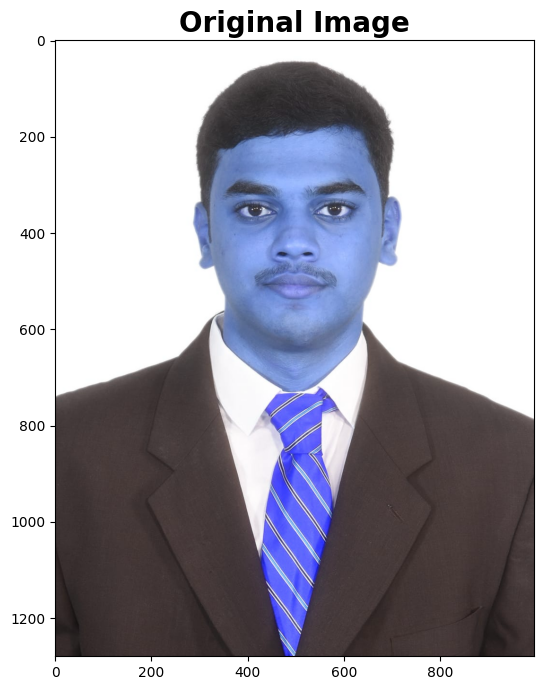

In [ ]:
# Displaying the Image using Matplotlib
plt.figure(figsize=(10, 8))
plt.title('Original Image',fontsize=20,fontweight='bold')
plt.imshow(image)

In [ ]:
image0 = cv2.imread("/content/Jabez Solomon - Photo.jpeg")
image1 = plt.imread("/content/Jabez Solomon - Photo.jpeg")
image2 = Image.open("/content/Jabez Solomon - Photo.jpeg")
image3 = np.array(Image.open("/content/Jabez Solomon - Photo.jpeg"))

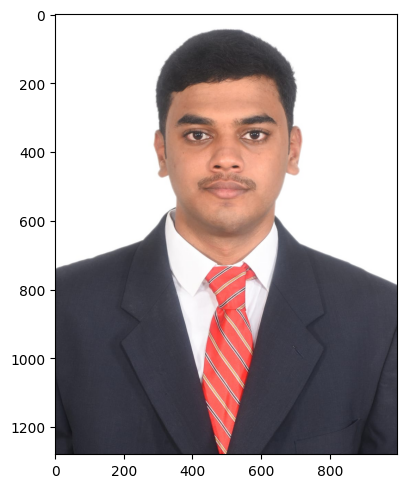

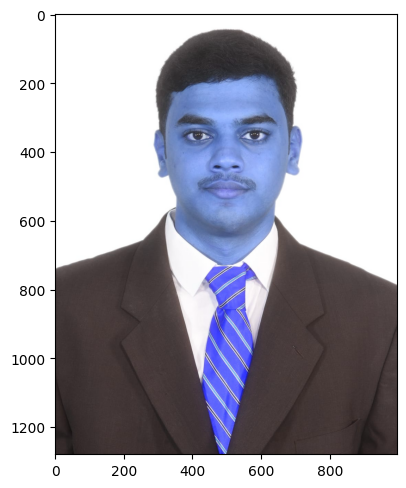

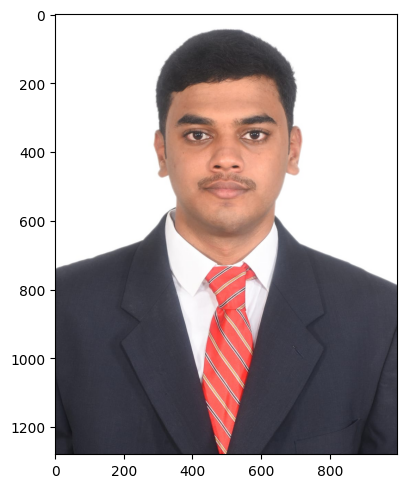

In [ ]:
fig = plt.figure(figsize=(15,15))
fig.add_subplot(1,3,1)
plt.imshow(image1)
fig = plt.figure(figsize=(15,15))
fig.add_subplot(1,3,2)
plt.imshow(image0)
fig = plt.figure(figsize=(15,15))
fig.add_subplot(1,3,3)
plt.imshow(image2)

In [ ]:
type(image)

numpy.ndarray

In [ ]:
image.shape

(1280, 995, 3)

In [ ]:
image.ndim

3

Gray scale

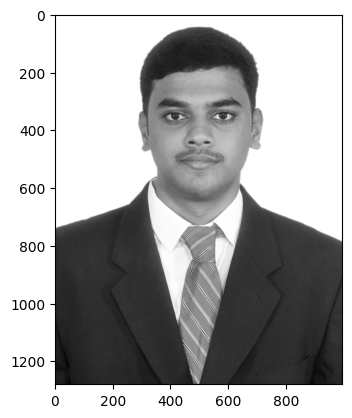

In [ ]:
image0_grayscale = image.sum(2)/255*3
plt.imshow(image0_grayscale,cmap = plt.get_cmap('gray'))

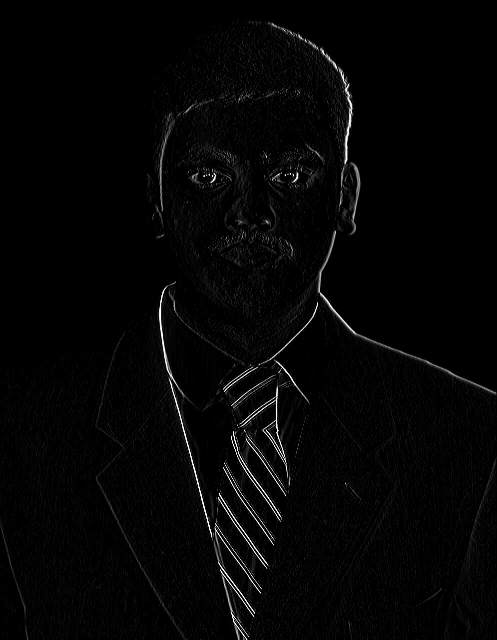

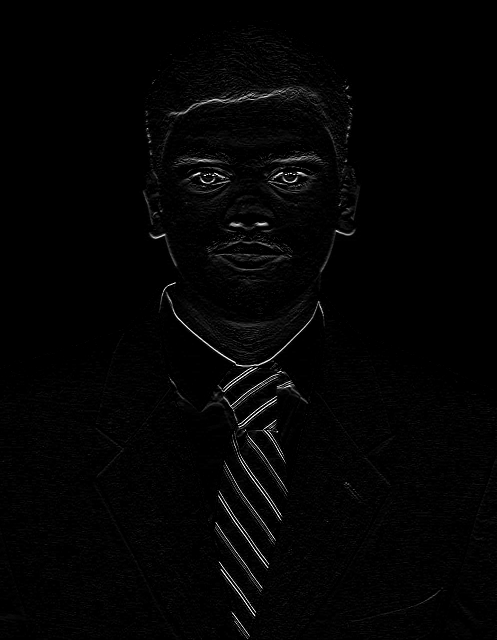

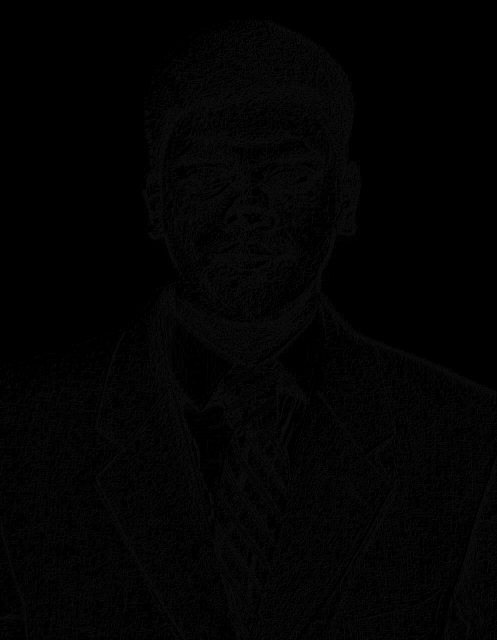

In [ ]:
import cv2
import numpy as np
from google.colab.patches import cv2_imshow

# Convert the image to grayscale
image = cv2.imread('/content/Jabez Solomon - Photo.jpeg')
gray_image = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)

# Define Sobel operator matrices for X and Y directions
sobel_x = np.array([[-1, 0, 1],
                    [-2, 0, 2],
                    [-1, 0, 1]])

sobel_y = np.array([[-1, -2, -1],
                    [0, 0, 0],
                    [1, 2, 1]])

# Convolve the image with Sobel X and Y operators
sobelx = cv2.filter2D(gray_image, -1, sobel_x)
sobely = cv2.filter2D(gray_image, -1, sobel_y)

# Combined X and Y Sobel Edge Detection
sobelxy = np.sqrt(sobelx**2 + sobely**2).astype(np.uint8)

# Resize the images to a smaller size (e.g., 50% of the original size)
scale_percent = 50  # Adjust the scale percentage as needed
width = int(image.shape[1] * scale_percent / 100)
height = int(image.shape[0] * scale_percent / 100)
sobelx_resized = cv2.resize(sobelx, (width, height))
sobely_resized = cv2.resize(sobely, (width, height))
sobelxy_resized = cv2.resize(sobelxy, (width, height))

# Display Sobel Edge Detection Images
cv2_imshow(sobelx_resized)
cv2_imshow(sobely_resized)
cv2_imshow(sobelxy_resized)


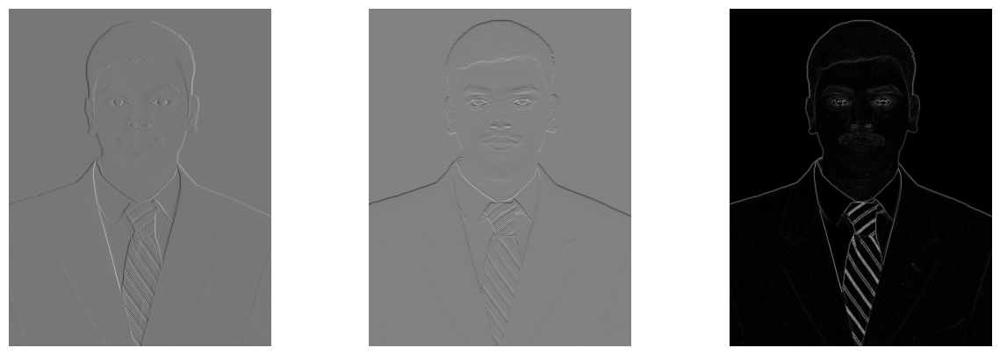

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

# Function to convert an RGB image to grayscale
def rgb_to_grayscale(img):
    return np.dot(img[..., :3], [0.2989, 0.5870, 0.1140]).astype(np.uint8)

# Function to apply a convolution filter manually
def convolve2d(image, kernel):
    image_h, image_w = image.shape
    kernel_h, kernel_w = kernel.shape
    output_h = image_h - kernel_h + 1
    output_w = image_w - kernel_w + 1
    new_image = np.zeros((output_h, output_w)).astype(np.float32)
    for y in range(0, output_h):
        for x in range(0, output_w):
            new_image[y, x] = np.sum(image[y:y+kernel_h, x:x+kernel_w] * kernel).astype(np.float32)
    return new_image

# Function to resize an image manually to 50% of its original size
def resize_image(image, scale_percent=50):
    new_width = int(image.shape[1] * scale_percent / 100)
    new_height = int(image.shape[0] * scale_percent / 100)
    new_image = np.zeros((new_height, new_width), dtype=np.float32)
    y_scale_factor = image.shape[0] / float(new_height)
    x_scale_factor = image.shape[1] / float(new_width)
    for y in range(new_height):
        for x in range(new_width):
            new_image[y, x] = image[int(y * y_scale_factor), int(x * x_scale_factor)]
    return new_image

# Sobel filters
sobel_x = np.array([[-1, 0, 1], [-2, 0, 2], [-1, 0, 1]])
sobel_y = np.array([[-1, -2, -1], [0, 0, 0], [1, 2, 1]])

# Convert the image to grayscale
gray_image = rgb_to_grayscale(image)

# Apply Sobel filters to the grayscale image
sobel_x_result = convolve2d(gray_image, sobel_x)
sobel_y_result = convolve2d(gray_image, sobel_y)

# Combined X and Y Sobel Edge Detection
sobel_combined = np.sqrt(np.square(sobel_x_result) + np.square(sobel_y_result))

# Resize the images to a smaller size (e.g., 50% of the original size)
sobel_x_resized = resize_image(sobel_x_result)
sobel_y_resized = resize_image(sobel_y_result)
sobel_combined_resized = resize_image(sobel_combined)

# Display the results
fig, axes = plt.subplots(1, 3, figsize=(15, 5))
axes[0].imshow(sobel_x_resized, cmap='gray')
axes[0].axis('off')
axes[1].imshow(sobel_y_resized, cmap='gray')
axes[1].axis('off')
axes[2].imshow(sobel_combined_resized, cmap='gray')
axes[2].axis('off')
plt.show()


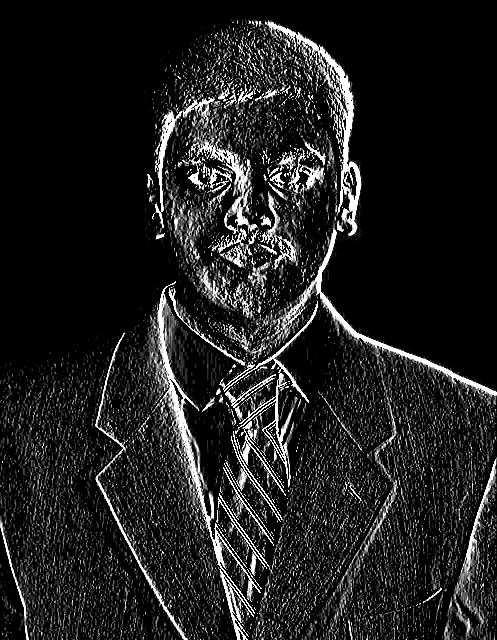

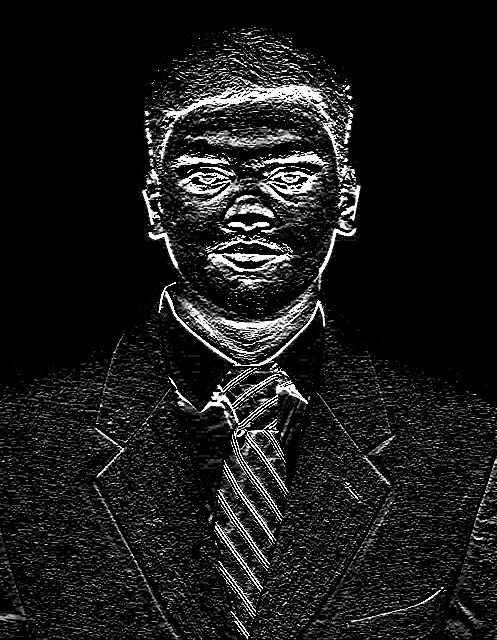

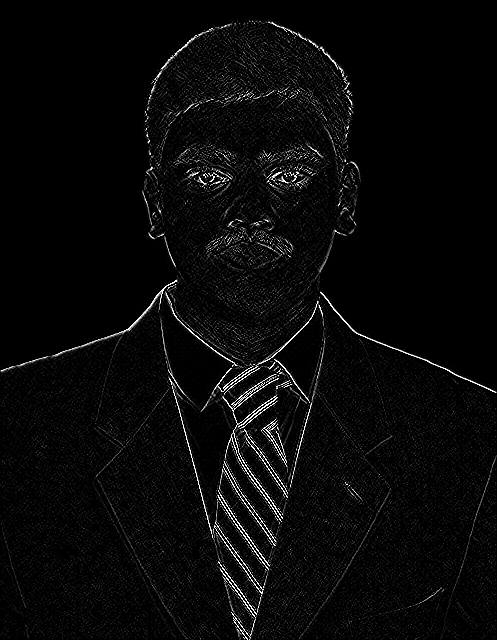

In [ ]:
from google.colab.patches import cv2_imshow
# Convert the image to grayscale
gray_image = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)

# Perform Sobel Edge Detection on the X axis
sobelx = cv2.Sobel(src=gray_image, ddepth=cv2.CV_64F, dx=1, dy=0, ksize=5)

# Perform Sobel Edge Detection on the Y axis
sobely = cv2.Sobel(src=gray_image, ddepth=cv2.CV_64F, dx=0, dy=1, ksize=5)

# Combined X and Y Sobel Edge Detection
sobelxy = cv2.Sobel(src=gray_image, ddepth=cv2.CV_64F, dx=1, dy=1, ksize=5)

# Resize the images to a smaller size (e.g., 50% of the original size)
scale_percent = 50  # Adjust the scale percentage as needed
width = int(image.shape[1] * scale_percent / 100)
height = int(image.shape[0] * scale_percent / 100)
sobelx_resized = cv2.resize(sobelx, (width, height))
sobely_resized = cv2.resize(sobely, (width, height))
sobelxy_resized = cv2.resize(sobelxy, (width, height))

# Display Sobel Edge Detection Images
cv2_imshow(sobelx_resized)

cv2_imshow(sobely_resized)

cv2_imshow(sobelxy_resized)


Canny EDGE Detection

In [ ]:
import numpy as np
import cv2

def custom_canny(image, low_threshold, high_threshold, gaussian_kernel_size=5, sobel_kernel_size=3):
    # Step 1: Gaussian Blur
    gaussian_kernel = np.outer(cv2.getGaussianKernel(gaussian_kernel_size, 0), cv2.getGaussianKernel(gaussian_kernel_size, 0))
    blurred_image = cv2.filter2D(image, -1, gaussian_kernel)

    # Step 2: Calculate gradients using Sobel operators
    sobel_x = np.array([[-1, 0, 1], [-2, 0, 2], [-1, 0, 1]])
    sobel_y = np.array([[-1, -2, -1], [0, 0, 0], [1, 2, 1]])

    gradient_x = cv2.filter2D(blurred_image, -1, sobel_x)
    gradient_y = cv2.filter2D(blurred_image, -1, sobel_y)

    # Step 3: Calculate gradient magnitude and direction
    gradient_magnitude = np.sqrt(gradient_x**2 + gradient_y**2)
    gradient_direction = np.arctan2(gradient_y, gradient_x)

    # Step 4: Non-maximum suppression
    height, width = gradient_magnitude.shape
    suppressed_edges = np.zeros_like(gradient_magnitude)

    for y in range(1, height - 1):
        for x in range(1, width - 1):
            angle = gradient_direction[y, x] * 180.0 / np.pi

            if (angle <= 22.5 or angle > 157.5) or (-22.5 <= angle < 22.5) or (angle >= -157.5):
                if (gradient_magnitude[y, x] >= gradient_magnitude[y, x + 1]) and (gradient_magnitude[y, x] >= gradient_magnitude[y, x - 1]):
                    suppressed_edges[y, x] = gradient_magnitude[y, x]
            elif (22.5 < angle <= 67.5) or (-112.5 <= angle < -67.5):
                if (gradient_magnitude[y, x] >= gradient_magnitude[y - 1, x + 1]) and (gradient_magnitude[y, x] >= gradient_magnitude[y + 1, x - 1]):
                    suppressed_edges[y, x] = gradient_magnitude[y, x]
            elif (67.5 < angle <= 112.5) or (-67.5 <= angle < -22.5):
                if (gradient_magnitude[y, x] >= gradient_magnitude[y - 1, x]) and (gradient_magnitude[y, x] >= gradient_magnitude[y + 1, x]):
                    suppressed_edges[y, x] = gradient_magnitude[y, x]
            elif (112.5 < angle <= 157.5) or (-22.5 <= angle < 22.5) or (angle < -157.5):
                if (gradient_magnitude[y, x] >= gradient_magnitude[y - 1, x - 1]) and (gradient_magnitude[y, x] >= gradient_magnitude[y + 1, x + 1]):
                    suppressed_edges[y, x] = gradient_magnitude[y, x]

    # Step 5: Double Thresholding and Edge Tracking by Hysteresis
    strong_edges = (suppressed_edges > high_threshold)
    weak_edges = (suppressed_edges >= low_threshold) & (suppressed_edges <= high_threshold)

    edges = np.zeros_like(image)
    edges[strong_edges] = 255

    for y in range(1, height - 1):
        for x in range(1, width - 1):
            if weak_edges[y, x]:
                if (strong_edges[y - 1:y + 2, x - 1:x + 2]).any():
                    edges[y, x] = 255

    return edges

# Load your image
image = cv2.imread('/content/gray.jpeg', cv2.IMREAD_GRAYSCALE)

# Apply custom Canny edge detection
canny_edges = custom_canny(image, low_threshold=30, high_threshold=80)

# Display the result
cv2.imwrite('canny.jpg', canny_edges)
cv2.waitKey(0)
cv2.destroyAllWindows()


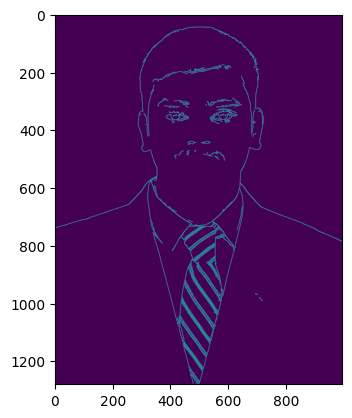

In [ ]:
canny = cv2.Canny(image,100,200)
plt.imshow(canny)

Laplacian Edge

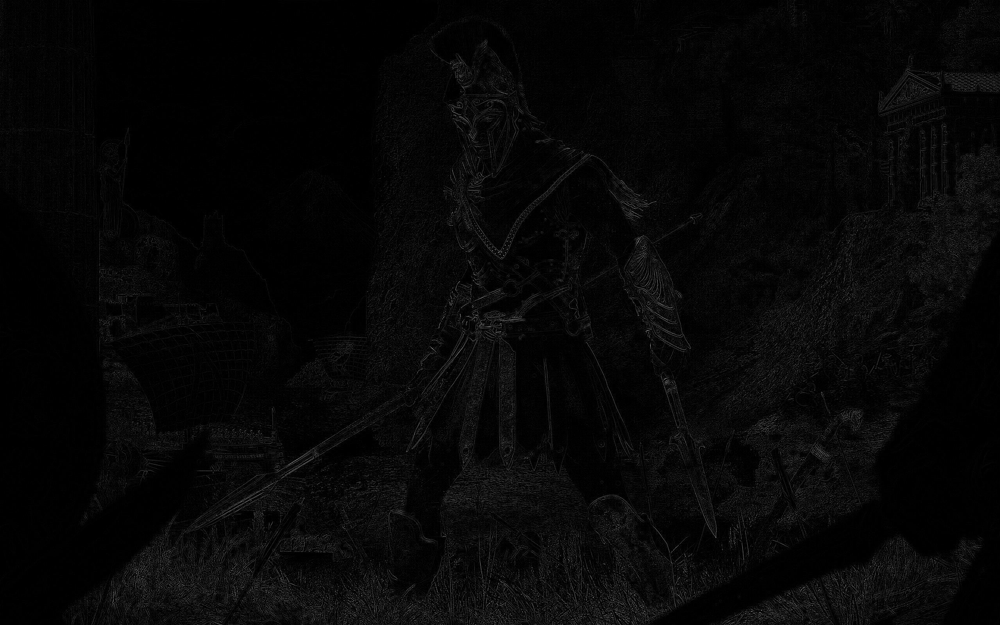

In [ ]:
import cv2
import numpy as np
from google.colab.patches import cv2_imshow
# Load the image
image = cv2.imread('/content/assassin-s-creed-odyssey-game-4k-wallpaper-2560x1600.jpg')
# Convert the image to grayscale
gray_image = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)

# Define the Laplacian kernel
laplacian_kernel = np.array([[0, 1, 0],
                              [1, -4, 1],
                              [0, 1, 0]])

# Apply the Laplacian filter
laplacian_result = cv2.filter2D(gray_image, -1, laplacian_kernel)

# Optionally, you can add the Laplacian result back to the original image to enhance the edges
laplacian_enhanced = cv2.add(gray_image, laplacian_result)

# Display the Laplacian edge detection result
cv2_imshow(laplacian_result)

# Display the enhanced image if desired
# cv2_imshow(laplacian_enhanced)


Prewitt Edge

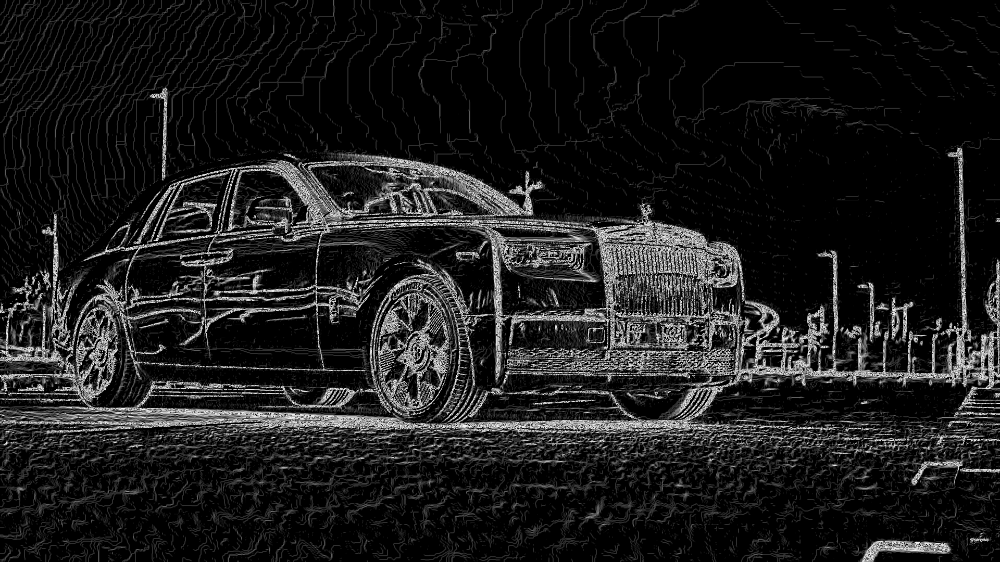

In [ ]:
import cv2
import numpy as np
from google.colab.patches import cv2_imshow

# Load the image in grayscale
image = cv2.imread('/content/rolls.jpg', cv2.IMREAD_GRAYSCALE)

# Define the Prewitt kernels for gradient calculation
prewitt_x = np.array([[-1, 0, 1],
                      [-1, 0, 1],
                      [-1, 0, 1]])

prewitt_y = np.array([[-1, -1, -1],
                      [0, 0, 0],
                      [1, 1, 1]])

# Convolve the image with Prewitt operators
gradient_x = cv2.filter2D(image, -1, prewitt_x)
gradient_y = cv2.filter2D(image, -1, prewitt_y)

# Calculate gradient magnitude
gradient_magnitude = np.sqrt(gradient_x**2 + gradient_y**2)

# Normalize the gradient magnitude manually to the range [0, 255]
gradient_magnitude = ((gradient_magnitude - gradient_magnitude.min()) / (gradient_magnitude.max() - gradient_magnitude.min()) * 255).astype(np.uint8)

# Display the Prewitt edge detection result
cv2_imshow(gradient_magnitude)

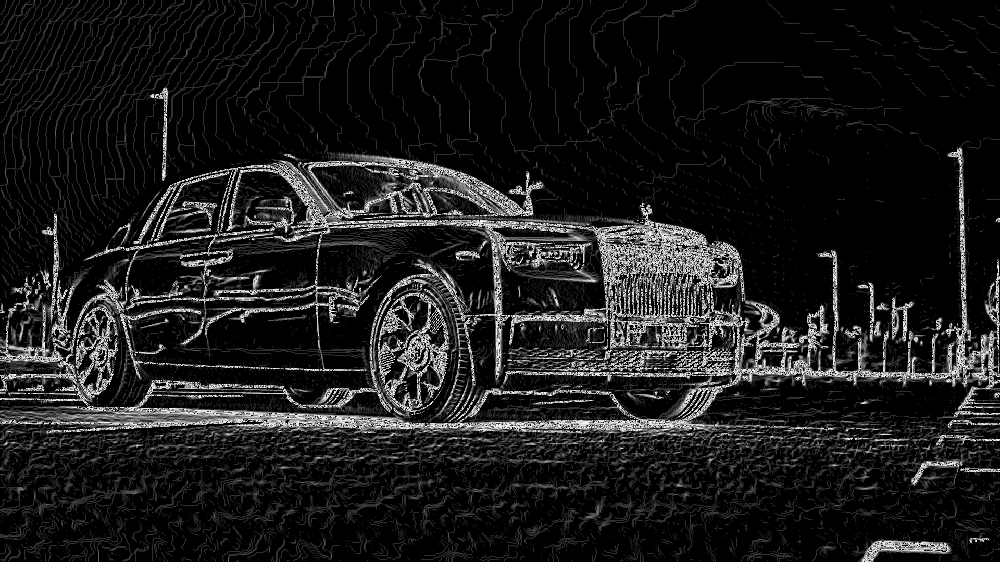

In [ ]:
import cv2
import numpy as np
from google.colab.patches import cv2_imshow

# Load the image in grayscale
image = cv2.imread('/content/rolls.jpg', cv2.IMREAD_GRAYSCALE)

# Apply Gaussian blur to reduce noise
blurred_image = cv2.GaussianBlur(image, (5, 5), 0)

# Define the Prewitt kernels for gradient calculation
prewitt_x = np.array([[-1, 0, 1],
                      [-1, 0, 1],
                      [-1, 0, 1]])

prewitt_y = np.array([[-1, -1, -1],
                      [0, 0, 0],
                      [1, 1, 1]])

# Convolve the blurred image with Prewitt operators
gradient_x = cv2.filter2D(blurred_image, -1, prewitt_x)
gradient_y = cv2.filter2D(blurred_image, -1, prewitt_y)

# Calculate gradient magnitude
gradient_magnitude = np.sqrt(gradient_x**2 + gradient_y**2)

# Normalize the gradient magnitude manually to the range [0, 255]
gradient_magnitude = ((gradient_magnitude - gradient_magnitude.min()) / (gradient_magnitude.max() - gradient_magnitude.min()) * 255).astype(np.uint8)

# Display the Prewitt edge detection result
cv2_imshow(gradient_magnitude)


Identity Kernel

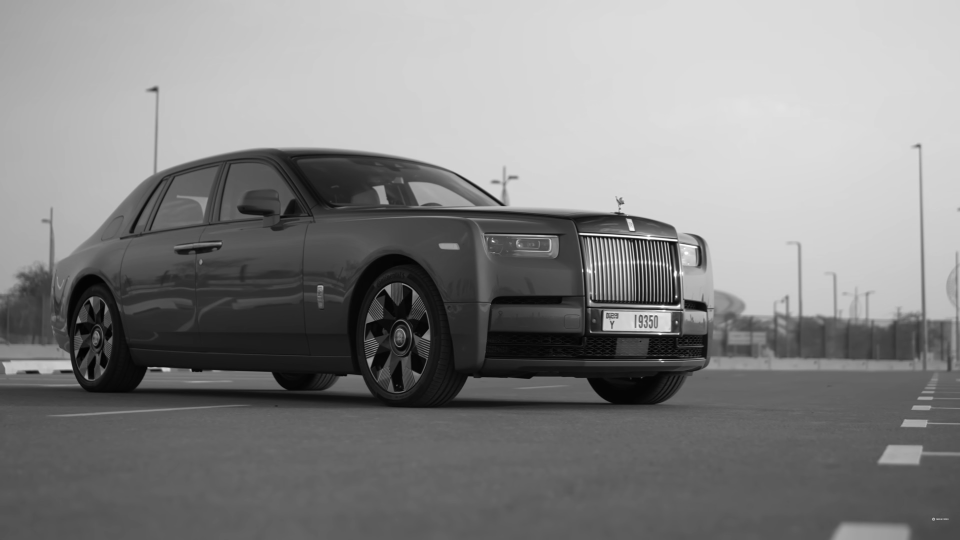

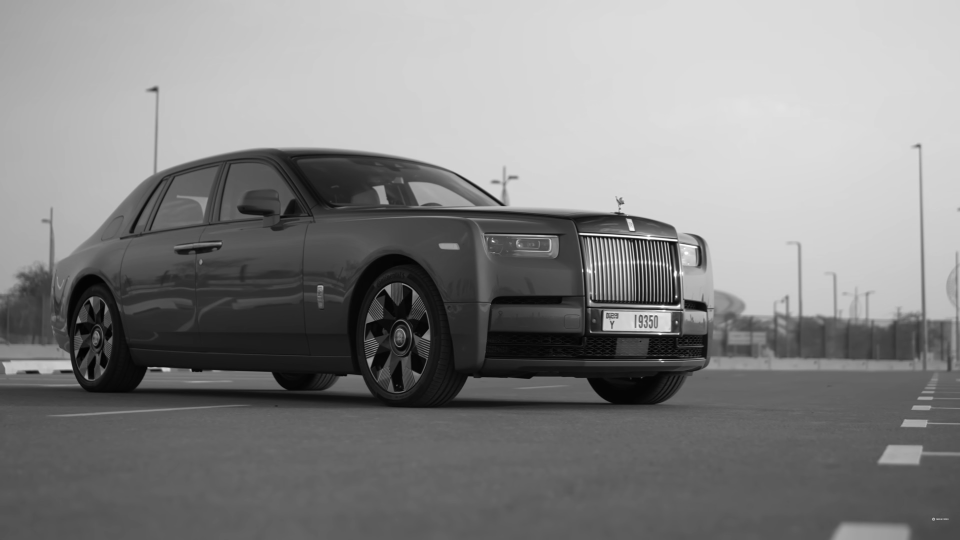

In [ ]:
# Define the identity kernel (3x3)
identity_kernel = np.array([[0, 0, 0],
                            [0, 1, 0],
                            [0, 0, 0]])

# Apply the identity kernel to the image using cv2.filter2D
identity_result = cv2.filter2D(image, -1, identity_kernel)

# Resize the images to a smaller size (e.g., 50% of the original size)
scale_percent = 50  # Adjust the scale percentage as needed
width = int(image.shape[1] * scale_percent / 100)
height = int(image.shape[0] * scale_percent / 100)

# Resize the processed image
identity_result_resized = cv2.resize(identity_result, (width, height))
image_rex = cv2.resize(image, (width, height))
# Display the resized identity result
cv2_imshow(identity_result_resized)
cv2_imshow(image_rex)

Identity Kernel

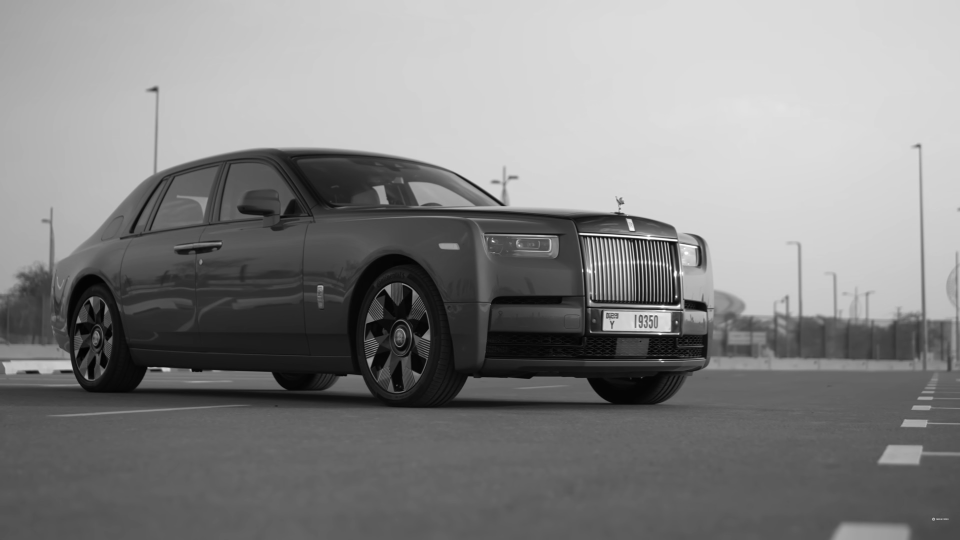

In [ ]:
# Define your custom blur kernel (e.g., a simple 3x3 averaging kernel)
custom_blur_kernel = np.array([[0, 0, 0],
                               [0, 1, 0],
                               [0, 0, 0]])

# Apply the custom blur kernel to the image using cv2.filter2D
blurred_image = cv2.filter2D(image, -1, custom_blur_kernel)

# Resize the images to a smaller size (e.g., 50% of the original size)
scale_percent = 50  # Adjust the scale percentage as needed
width = int(image.shape[1] * scale_percent / 100)
height = int(image.shape[0] * scale_percent / 100)

# Resize the processed image
blurred_image_resized = cv2.resize(blurred_image, (width, height))

# Display the resized blurred image
cv2_imshow(blurred_image_resized)

Sharpening

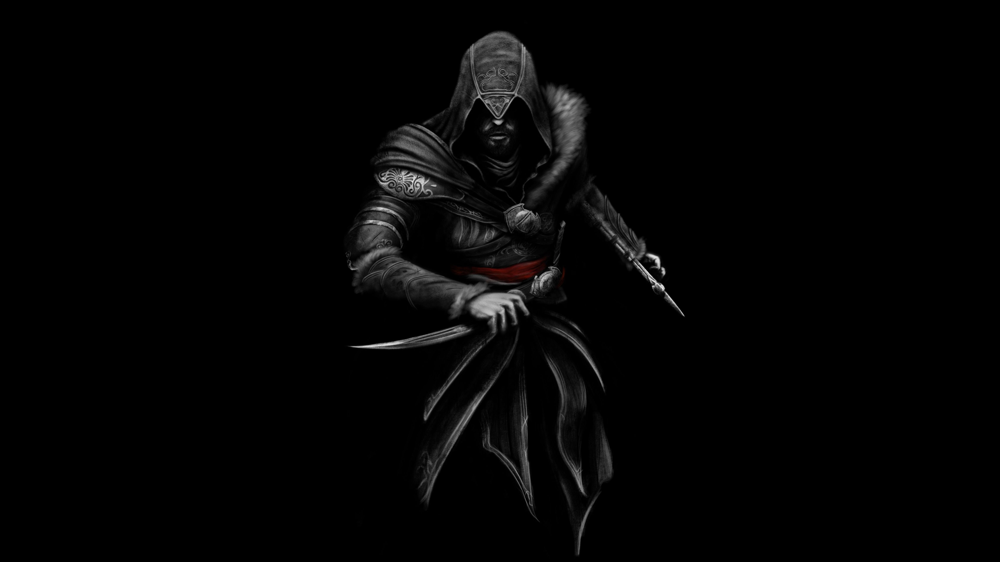

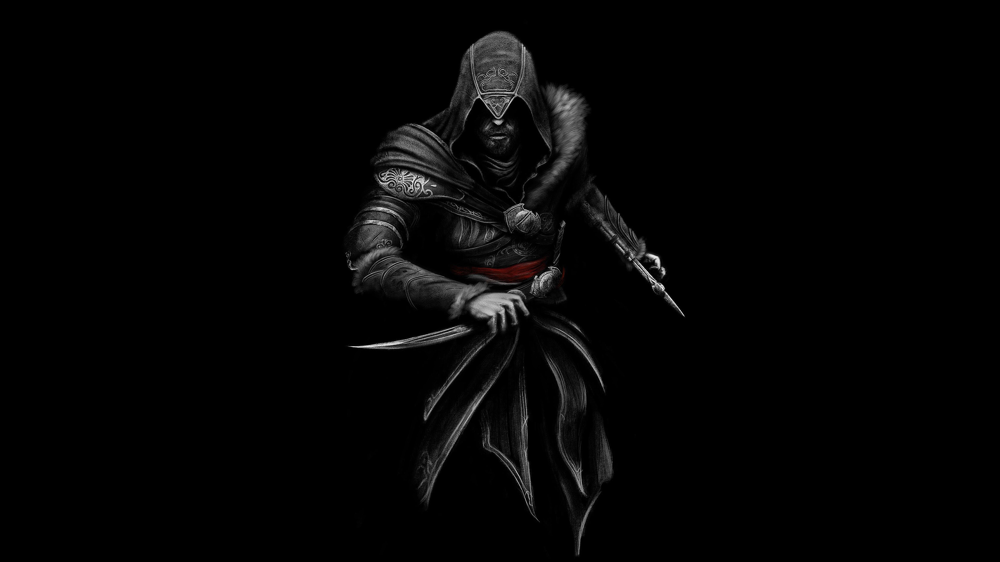

In [ ]:
# Read the image
image = cv2.imread('/content/as.jpg')

# Define a custom sharpening kernel
sharpening_kernel = np.array([[-1, -1, -1],
                              [-1,  9, -1],
                              [-1, -1, -1]])

# Apply the custom kernel to the image using cv2.filter2D
sharpened_image = cv2.filter2D(image, -1, sharpening_kernel)

# Display the original and sharpened images
cv2_imshow(image)
cv2_imshow(sharpened_image)

Trying with types of kernel

In [ ]:
# Read the image
image = cv2.imread('/content/best_frame.jpg')

# Edge detection kernel
edge_detection_kernel = np.array([[1, 0, -1], [0, 0, 0], [-1, 0, 1]])

# Box Blur kernel
box_blur_kernel = np.ones((3, 3), np.float32) / 9

# Emboss kernel
emboss_kernel = np.array([[-2, -1, 0], [-1, 1, 1], [0, 1, 2]])

# Apply each kernel using filter2D
edge_image = cv2.filter2D(image, -1, edge_detection_kernel)
box_blur_image = cv2.filter2D(image, -1, box_blur_kernel)
emboss_image = cv2.filter2D(image, -1, emboss_kernel)

# Save the images to files
cv2.imwrite('edge_image.jpg', edge_image)
cv2.imwrite('box_blur_image.jpg', box_blur_image)
cv2.imwrite('emboss_image.jpg', emboss_image)

# Provide the paths to the saved images
paths = {
    "edge_image": '/mnt/data/edge_image.jpg',
    "box_blur_image": '/mnt/data/box_blur_image.jpg',
    "emboss_image": '/mnt/data/emboss_image.jpg'
}

paths

{'edge_image': '/mnt/data/edge_image.jpg',
 'box_blur_image': '/mnt/data/box_blur_image.jpg',
 'emboss_image': '/mnt/data/emboss_image.jpg'}

17 x 17 Gaussian Blur

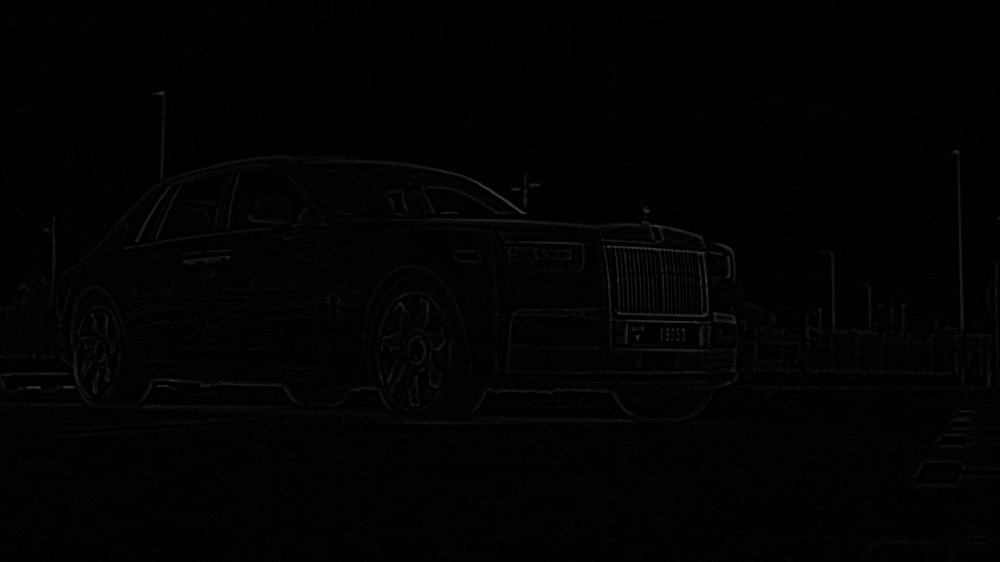

In [ ]:
import cv2
import numpy as np
from google.colab.patches import cv2_imshow

# Load the image in grayscale
image = cv2.imread('/content/rolls.jpg', cv2.IMREAD_GRAYSCALE)

# Define the size of the LoG filter (17x17)
filter_size = (17, 17)

# Define the standard deviation (sigma) for the Gaussian smoothing
sigma = 3.0

# Create a 2D Gaussian kernel
x, y = np.meshgrid(np.arange(-filter_size[0] // 2 + 1, filter_size[0] // 2 + 1),
                   np.arange(-filter_size[1] // 2 + 1, filter_size[1] // 2 + 1))
gaussian_kernel = np.exp(-(x**2 + y**2) / (2 * sigma**2))

# Normalize the Gaussian kernel
gaussian_kernel /= np.sum(gaussian_kernel)

# Apply the Gaussian smoothing to the image
smoothed_image = cv2.filter2D(image, -1, gaussian_kernel)

# Create the Laplacian kernel
laplacian_kernel = np.array([[0, 0, 1, 0, 0],
                             [0, 1, 2, 1, 0],
                             [1, 2, -16, 2, 1],
                             [0, 1, 2, 1, 0],
                             [0, 0, 1, 0, 0]])

# Apply the Laplacian filter to the smoothed image
log_result = cv2.filter2D(smoothed_image, -1, laplacian_kernel)

# Display the Laplacian of Gaussian result
cv2_imshow(log_result)


Applying Canny edge detection using custom matrix operations on a video frame-by-frame

In [ ]:
import cv2
import numpy as np

# Open the video file
video_path = '/content/Call of a Bald Eagle.mp4'
cap = cv2.VideoCapture(video_path)

# Get the original video's width, height, and frame rate
frame_width = int(cap.get(3))
frame_height = int(cap.get(4))
fps = cap.get(5)

# Define the codec and create a VideoWriter object
output_path = '/content/edge_output.mp4'
fourcc = cv2.VideoWriter_fourcc(*'MP4V')
out = cv2.VideoWriter(output_path, fourcc, fps, (frame_width, frame_height), isColor=False)

while cap.isOpened():
    ret, frame = cap.read()

    if not ret:
        break

    # Convert the frame to grayscale
    gray_frame = cv2.cvtColor(frame, cv2.COLOR_BGR2GRAY)

    # Define Gaussian kernel for blurring
    gaussian_kernel = np.array([[1, 2, 1],
                                 [2, 4, 2],
                                 [1, 2, 1]]) / 16.0

    # Apply Gaussian blur
    blurred_frame = cv2.filter2D(gray_frame, -1, gaussian_kernel)

    # Define Sobel operators for gradient calculation
    sobel_x = np.array([[-1, 0, 1],
                        [-2, 0, 2],
                        [-1, 0, 1]])

    sobel_y = np.array([[-1, -2, -1],
                        [0, 0, 0],
                        [1, 2, 1]])

    # Convolve the blurred frame with Sobel operators
    gradient_x = cv2.filter2D(blurred_frame, -1, sobel_x)
    gradient_y = cv2.filter2D(blurred_frame, -1, sobel_y)

    # Calculate gradient magnitude
    gradient_magnitude = np.sqrt(gradient_x**2 + gradient_y**2)

    # Adjust the thresholds based on the frame's statistics
    max_threshold = np.max(gradient_magnitude)
    low_threshold = 0.1 * max_threshold  # Adjust these factors as needed
    high_threshold = 0.3 * max_threshold

    # Initialize an output frame with zeros
    edges = np.zeros_like(gradient_magnitude, dtype=np.uint8)

    # Apply double thresholding and edge tracking by hysteresis
    edges[(gradient_magnitude >= high_threshold)] = 255
    edges[(gradient_magnitude <= low_threshold)] = 0

    for i in range(1, edges.shape[0] - 1):
        for j in range(1, edges.shape[1] - 1):
            if low_threshold < gradient_magnitude[i, j] < high_threshold:
                if (gradient_magnitude[i-1:i+2, j-1:j+2] >= high_threshold).any():
                    edges[i, j] = 255

    # Write the processed frame to the output video
    out.write(edges)

# Release the video capture and VideoWriter
cap.release()
out.release()

print(f"Video saved as {output_path}")


Video saved as /content/edge_output.mp4


In [ ]:
import cv2
import numpy as np

# Open the video file
video_path = '/content/Call of a Bald Eagle.mp4'
cap = cv2.VideoCapture(video_path)

# Get the original video's width, height, and frame rate
frame_width = int(cap.get(3))
frame_height = int(cap.get(4))
fps = cap.get(5)

# Define the codec and create a VideoWriter object for Laplacian edges
laplacian_output_path = '/content/laplacian_output.mp4'
laplacian_fourcc = cv2.VideoWriter_fourcc(*'MP4V')
laplacian_out = cv2.VideoWriter(laplacian_output_path, laplacian_fourcc, fps, (frame_width, frame_height), isColor=False)

# Laplacian kernel
laplacian_kernel = np.array([[0, -1, 0], [-1, 4, -1], [0, -1, 0]])

while cap.isOpened():
    ret, frame = cap.read()

    if not ret:
        break

    # Convert the frame to grayscale
    gray_frame = cv2.cvtColor(frame, cv2.COLOR_BGR2GRAY)

    # Apply Laplacian edge detection using the custom kernel
    laplacian_edges = cv2.filter2D(gray_frame, -1, laplacian_kernel)

    # Write the Laplacian edge frame to the output video
    laplacian_out.write(cv2.convertScaleAbs(laplacian_edges))

# Release the video capture and VideoWriter
cap.release()
laplacian_out.release()

print(f"Laplacian edges video saved as {laplacian_output_path}")


Laplacian edges video saved as /content/laplacian_output.mp4


Creating a custom edge detection filter from scratch, without relying on built-in functions, involves manually implementing the convolution process. We'll design a simple edge detection filter and apply it to each frame of the video. Note that custom filters might not be as efficient or effective as standard ones, but they can be useful for learning purposes or for achieving unique effects.

In [ ]:
import cv2
import numpy as np

def custom_edge_detection(image, kernel):
    """Apply custom edge detection using convolution."""
    # Get dimensions of the image and kernel
    img_height, img_width = image.shape
    kernel_height, kernel_width = kernel.shape

    # Create an empty image for the output
    output = np.zeros_like(image)

    # Pad the image with zeros around the border
    pad_height = kernel_height // 2
    pad_width = kernel_width // 2
    padded_image = np.pad(image, ((pad_height, pad_height), (pad_width, pad_width)), 'constant')

    # Convolution process
    for i in range(img_height):
        for j in range(img_width):
            # Apply the kernel
            output[i, j] = np.sum(kernel * padded_image[i:i+kernel_height, j:j+kernel_width])

    return output

# Open the video file
video_path = '/content/Call of a Bald Eagle.mp4'
cap = cv2.VideoCapture(video_path)

# Get the original video's width, height, and frame rate
frame_width = int(cap.get(3))
frame_height = int(cap.get(4))
fps = cap.get(5)

# Define the codec and create a VideoWriter object
output_path = '/content/custom_edge_output.mp4'
fourcc = cv2.VideoWriter_fourcc(*'MP4V')
out = cv2.VideoWriter(output_path, fourcc, fps, (frame_width, frame_height), isColor=False)

# Custom edge detection kernel
kernel = np.array([[-1, -1, -1],
                   [-1,  8, -1],
                   [-1, -1, -1]])

while cap.isOpened():
    ret, frame = cap.read()

    if not ret:
        break

    # Convert the frame to grayscale
    gray_frame = cv2.cvtColor(frame, cv2.COLOR_BGR2GRAY)

    # Apply custom edge detection
    edges = custom_edge_detection(gray_frame, kernel)

    # Normalize and write the edge frame to the output video
    edges_normalized = cv2.convertScaleAbs(edges)
    out.write(edges_normalized)

# Release the video capture and VideoWriter
cap.release()
out.release()

print(f"Custom edge detection video saved as {output_path}")


Custom edge detection video saved as /content/custom_edge_output.mp4


Define the 5x5 Sobel kernels for horizontal (Gx) and vertical (Gy) gradients.
Convert the input image to grayscale.
Apply convolution with both kernels to the grayscale image.
Combine the horizontal and vertical gradients to obtain the edge magnitude.
Normalize the edge magnitude to fit within an image format.
build a python code with matrix

In [ ]:
import cv2
import numpy as np

def custom_convolution(image, kernel):
    """Apply convolution with a custom kernel."""
    kernel_size = kernel.shape[0]
    pad_size = kernel_size // 2
    padded_image = np.pad(image, pad_size, mode='constant')
    output = np.zeros_like(image)

    for i in range(image.shape[0]):
        for j in range(image.shape[1]):
            output[i, j] = np.sum(kernel * padded_image[i:i+kernel_size, j:j+kernel_size])
    return output

# Load the image and convert to grayscale
image_path = '/content/cus edge.jpg'  # Replace with your image path
image = cv2.imread(image_path, 0)

# Define the 5x5 Sobel kernels
Gx = np.array([[-2, -1, 0, 1, 2],
               [-2, -1, 0, 1, 2],
               [-4, -2, 0, 2, 4],
               [-2, -1, 0, 1, 2],
               [-2, -1, 0, 1, 2]])
Gy = np.array([[-2, -2, -4, -2, -2],
               [-1, -1, -2, -1, -1],
               [ 0,  0,  0,  0,  0],
               [ 1,  1,  2,  1,  1],
               [ 2,  2,  4,  2,  2]])

# Apply convolution with the Sobel kernels
convolved_Gx = custom_convolution(image, Gx)
convolved_Gy = custom_convolution(image, Gy)

# Calculate edge magnitude
edge_magnitude = np.sqrt(convolved_Gx**2 + convolved_Gy**2)

# Display the result
cv2.imwrite('cusedgemani.png',edge_magnitude)
cv2.waitKey(0)
cv2.destroyAllWindows()


Overlaying Histograms: You can overlay histograms on images to visualize the distribution of pixel values:

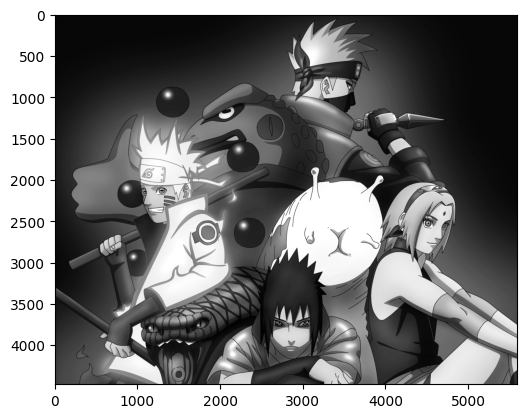

In [ ]:

image = cv2.imread('/content/a2.jpg', cv2.IMREAD_GRAYSCALE)

# Plot a histogram on the image
plt.hist(image.ravel(), bins=256, range=(0, 256), density=True, color='blue', alpha=0.7)

# Display the image with the histogram
plt.imshow(image, cmap='gray')
plt.show()


Contour Plotting:
Use contour plots to visualize level curves or contours on images:

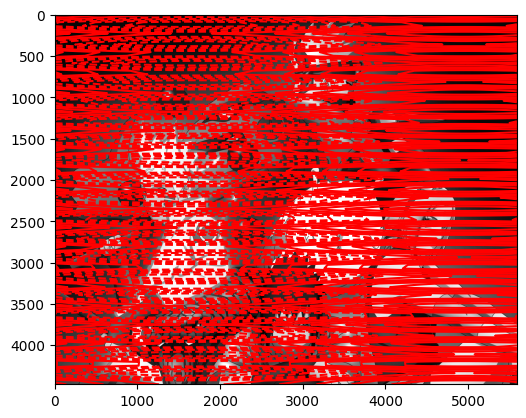

In [ ]:
image = cv2.imread('/content/a2.jpg', cv2.IMREAD_GRAYSCALE)

# Create data for contour plot
x = np.linspace(0, image.shape[1], 100)
y = np.linspace(0, image.shape[0], 100)
X, Y = np.meshgrid(x, y)
Z = np.sin(X) + np.cos(Y)

# Plot contours on the image
plt.contour(X, Y, Z, levels=10, colors='red')

# Display the image with contours
plt.imshow(image, cmap='gray')
plt.show()


Heatmaps: Generate and overlay heatmaps on images to represent intensity or density information:

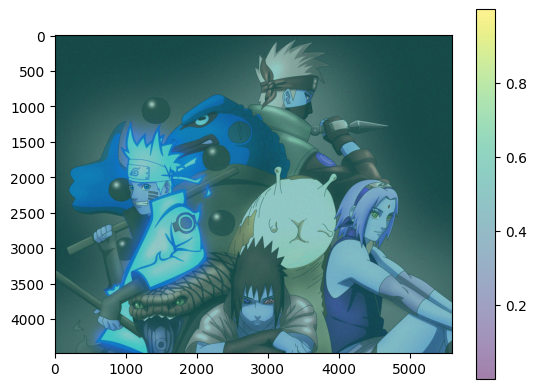

In [ ]:
image = cv2.imread('/content/a2.jpg', cv2.IMREAD_COLOR)

# Create a heatmap data
heatmap = np.random.rand(image.shape[0], image.shape[1])

# Overlay the heatmap on the image
plt.imshow(image)
plt.imshow(heatmap, alpha=0.5, cmap='viridis', interpolation='bilinear')
plt.colorbar()
plt.show()


Scatter Plots: Visualize scatter plots on images to represent data points or coordinates:



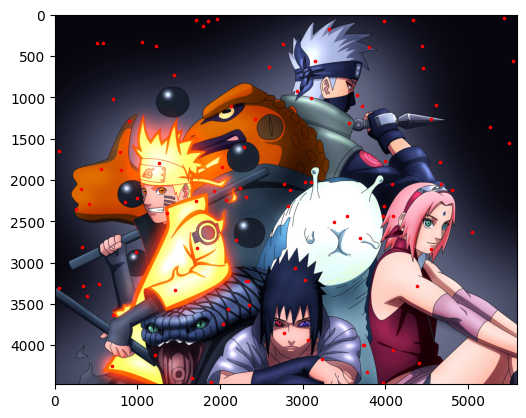

In [ ]:
image = cv2.imread('/content/a2.jpg')

# Generate random data points
x = np.random.randint(0, image.shape[1], size=100)
y = np.random.randint(0, image.shape[0], size=100)

# Plot the data points on the image
plt.scatter(x, y, c='red', marker='.', s=10)

# Display the image with scatter plot
plt.imshow(cv2.cvtColor(image, cv2.COLOR_BGR2RGB))
plt.show()

Bar Charts: Create bar charts or bar graphs overlaid on images to represent data with bars

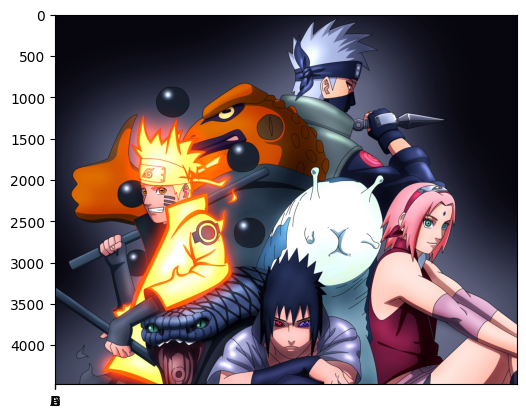

In [ ]:
# Load an image
image = cv2.imread('/content/a2.jpg')

# Define data for the bar chart
categories = ['A', 'B', 'C', 'D']
values = [10, 20, 15, 30]

# Plot a bar chart on the image
plt.bar(categories, values, color='blue')

# Display the image with the bar chart
plt.imshow(cv2.cvtColor(image, cv2.COLOR_BGR2RGB))
plt.show()


 multi-scale edge detection using the Laplacian of Gaussian (LoG) filter.


In [ ]:
image = cv2.imread('/content/a2.jpg', cv2.IMREAD_GRAYSCALE)

# Define a list of scales (sigma values for LoG)
scales = [1, 2, 3]

# Perform edge detection at different scales
edges_multi_scale = []
for scale in scales:
    blurred = cv2.GaussianBlur(image, (0, 0), sigmaX=scale)
    edges = cv2.Laplacian(blurred, cv2.CV_64F)
    edges_multi_scale.append(edges)

# Combine edge maps (e.g., using maximum or weighted combination)
combined_edges = np.max(edges_multi_scale, axis=0)

# Display the combined edge map
cv2.imwrite('0.png', combined_edges)
cv2.waitKey(0)
cv2.destroyAllWindows()


 Haralick texture features from a grayscale image using the Mahotas library. Haralick texture features are statistical measures that describe the texture of an image. These features can be used for tasks like texture classification or texture-based edge detection.

In [ ]:
!pip install mahotas

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 5.4/5.4 MB 22.9 MB/s eta 0:00:00


In [ ]:
import mahotas as mh

# Load a grayscale image
image = cv2.imread('/content/a2.jpg', cv2.IMREAD_GRAYSCALE)

# Calculate Haralick texture features
features = mh.features.haralick(image).mean(axis=0)

# Display texture features (can be used for texture-based edge detection)
print("Haralick Texture Features:")
print(features)

Haralick Texture Features:
[ 8.53838738e-03  1.02861098e+02  9.91795365e-01  6.26845477e+03
  8.44053095e-01  1.76754129e+02  2.49709580e+04  8.03523269e+00
  8.91834184e+00  2.35682429e-03  1.41081866e+00 -7.97065290e-01
  9.99996210e-01]


Histogram-Based Methods (Otsu's Thresholding): Otsu's method is used for threshold selection.

In [ ]:
image = cv2.imread('/content/a2.jpg', cv2.IMREAD_GRAYSCALE)

# Apply Otsu's thresholding
_, thresholded = cv2.threshold(image, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)

# Display the thresholded image
cv2.imwrite('edges13.png',  thresholded)
cv2.waitKey(0)
cv2.destroyAllWindows()

Color-Based Edge Detection (Channel-wise): In color images, you can perform edge detection separately in individual color channels (e.g., RGB) and then combine the results to obtain color-based edge detection. Here's an example using OpenCV to perform edge detection in the red channel:

In [ ]:
image = cv2.imread('/content/a2.jpg')

# Extract the red channel
red_channel = image[:, :, 2]

# Apply edge detection to the red channel (e.g., using Canny)
edges_red = cv2.Canny(red_channel, 100, 200)

# Display the edge-detected red channel
cv2.imwrite('edges12.png',  edges_red)
cv2.waitKey(0)
cv2.destroyAllWindows()


 evaluate the performance of an edge detection algorithm by comparing its results to ground truth edges. It calculates precision, recall, and F1 score as evaluation metrics.

In [ ]:
import cv2
import numpy as np
from sklearn.metrics import precision_score, recall_score, f1_score

# Read the input image
input_image = cv2.imread('/content/a2.jpg', cv2.IMREAD_GRAYSCALE)
# Define the ground truth edges image
ground_truth_edges = cv2.imread('/content/binary_edge_image.jpg', cv2.IMREAD_GRAYSCALE)

# Resize the input image to match the ground truth
input_image = cv2.resize(input_image, (ground_truth_edges.shape[1], ground_truth_edges.shape[0]))

# Threshold the ground truth edges image
_, ground_truth_edges = cv2.threshold(ground_truth_edges, 127, 200, cv2.THRESH_BINARY)

# Calculate the true positives, false positives, and false negatives
tp = np.count_nonzero(np.logical_and(ground_truth_edges, input_image))
fp = np.count_nonzero(np.logical_and(np.logical_not(ground_truth_edges), input_image))
fn = np.count_nonzero(np.logical_and(ground_truth_edges, np.logical_not(input_image)))

# Calculate the precision, recall, and F1 score with average='binary'
precision = precision_score(ground_truth_edges.flatten(), input_image.flatten(), average=None)
recall = recall_score(ground_truth_edges.flatten(), input_image.flatten(), average=None)
f1 = f1_score(ground_truth_edges.flatten(), input_image.flatten(), average=None)

print(f'Precision: {precision:.3f}')
print(f'Recall: {recall:.3f}')
print(f'F1 score: {f1:.3f}')


/usr/local/lib/python3.10/dist-packages/sklearn/metrics/_classification.py:1344: UndefinedMetricWarning: Recall is ill-defined and being set to 0.0 in labels with no true samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, msg_start, len(result))


TypeError: unsupported format string passed to numpy.ndarray.__format__

image segmentation and edge detection using traditional computer vision methods.

In [ ]:
# Load an image
image = cv2.imread('/content/a2.jpg')

# Convert the image to RGB format
image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

# Reshape the image to a 2D array of pixels and 3 color values (RGB)
pixel_values = image.reshape((-1, 3))

# Convert to float
pixel_values = np.float32(pixel_values)

# Define stopping criteria
criteria = (cv2.TERM_CRITERIA_EPS + cv2.TERM_CRITERIA_MAX_ITER, 100, 0.2)

# Number of clusters (K)
k = 3

# Perform K-means clustering
_, labels, (centers) = cv2.kmeans(pixel_values, k, None, criteria, 10, cv2.KMEANS_RANDOM_CENTERS)

# Convert back to 8-bit pixel values
centers = np.uint8(centers)

# Flatten the labels array
labels = labels.flatten()

# Create the segmented image
segmented_image = centers[labels.flatten()]

# Reshape back to the original image dimension
segmented_image = segmented_image.reshape(image.shape)

# Convert the segmented image to grayscale
segmented_gray = cv2.cvtColor(segmented_image, cv2.COLOR_RGB2GRAY)

# Apply threshold to the segmented image
_, segmented_thresh = cv2.threshold(segmented_gray, 127, 255, cv2.THRESH_BINARY)

# Apply edge detection using the Canny method with adjustable thickness
edges = cv2.Canny(segmented_thresh, 100, 200, apertureSize=3)

# Apply Sobel filters to the segmented image
sobel_x = cv2.Sobel(segmented_gray, cv2.CV_64F, 1, 0, ksize=5)
sobel_y = cv2.Sobel(segmented_gray, cv2.CV_64F, 0, 1, ksize=5)

# Calculate the gradient magnitude and direction
gradient_magnitude = np.sqrt(sobel_x**2 + sobel_y**2)
gradient_direction = np.arctan(sobel_y / sobel_x) * 180 / np.pi

# Apply threshold to the gradient magnitude
_, gradient_magnitude_thresh = cv2.threshold(gradient_magnitude, 50, 255, cv2.THRESH_BINARY)

# Apply threshold to the gradient direction
_, gradient_direction_thresh = cv2.threshold(gradient_direction, 45, 255, cv2.THRESH_BINARY)

# Combine the gradient magnitude and direction thresholds
edge_sobel = cv2.bitwise_and(gradient_magnitude_thresh, gradient_direction_thresh)

cv2.imwrite('edges5.png',   image)
cv2.imwrite('edges6.png',  segmented_image)
cv2.imwrite('edges7.png',   sobel_x)
cv2.imwrite('edges8.png',   sobel_y)
cv2.imwrite('edges9.png',  edges)
cv2.imwrite('edges10.png',  edge_sobel)


<ipython-input-89-c0ceb26d4eb3>:49: RuntimeWarning: divide by zero encountered in divide
  gradient_direction = np.arctan(sobel_y / sobel_x) * 180 / np.pi
<ipython-input-89-c0ceb26d4eb3>:49: RuntimeWarning: invalid value encountered in divide
  gradient_direction = np.arctan(sobel_y / sobel_x) * 180 / np.pi


True

In [ ]:
import cv2
import numpy as np

# Load an image
image = cv2.imread('/content/new as.jpg')

# Convert the image to RGB format
image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

# Reshape the image to a 2D array of pixels and 3 color values (RGB)
pixel_values = image.reshape((-1, 3))

# Convert to float
pixel_values = np.float32(pixel_values)

# Define stopping criteria
criteria = (cv2.TERM_CRITERIA_EPS + cv2.TERM_CRITERIA_MAX_ITER, 100, 0.2)

# Number of clusters (K)
k = 3

# Perform K-means clustering
_, labels, (centers) = cv2.kmeans(pixel_values, k, None, criteria, 10, cv2.KMEANS_RANDOM_CENTERS)

# Convert back to 8-bit pixel values
centers = np.uint8(centers)

# Flatten the labels array
labels = labels.flatten()

# Create the segmented image
segmented_image = centers[labels.flatten()]

# Reshape back to the original image dimension
segmented_image = segmented_image.reshape(image.shape)

# Convert the segmented image to grayscale
segmented_gray = cv2.cvtColor(segmented_image, cv2.COLOR_RGB2GRAY)

# Apply threshold to the segmented image
_, segmented_thresh = cv2.threshold(segmented_gray, 127, 255, cv2.THRESH_BINARY)

# Apply edge detection using the Canny method with adjustable thickness
edges = cv2.Canny(segmented_thresh, 100, 200, apertureSize=3)

# Save the edge image as a PNG file
cv2.imwrite('edges0.png', edges)

# Display the original image, segmented image, thresholded image, and edge detected image
cv2.imwrite('edges24.png',image)
cv2.imwrite('edges34.png',segmented_image)
cv2.imwrite('edges44.png',  segmented_thresh)

# Wait for a key press and close the image window
cv2.waitKey(0)
cv2.destroyAllWindows()

error: OpenCV(4.8.0) /io/opencv/modules/imgproc/src/color.cpp:182: error: (-215:Assertion failed) !_src.empty() in function 'cvtColor'


In [ ]:
import cv2
import numpy as np
from google.colab.patches import cv2_imshow
# Load an image
image = cv2.imread('/content/new as.jpg')

# Convert the image to RGB format
image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

# Reshape the image to a 2D array of pixels and 3 color values (RGB)
pixel_values = image.reshape((-1, 3))

# Convert to float
pixel_values = np.float32(pixel_values)

# Define stopping criteria
criteria = (cv2.TERM_CRITERIA_EPS + cv2.TERM_CRITERIA_MAX_ITER, 100, 0.2)

# Number of clusters (K)
k = 3

# Perform K-means clustering
_, labels, (centers) = cv2.kmeans(pixel_values, k, None, criteria, 10, cv2.KMEANS_RANDOM_CENTERS)

# Convert back to 8-bit pixel values
centers = np.uint8(centers)

# Flatten the labels array
labels = labels.flatten()

# Create the segmented image
segmented_image = centers[labels.flatten()]

# Reshape back to the original image dimension
segmented_image = segmented_image.reshape(image.shape)

# Convert the segmented image to grayscale
segmented_gray = cv2.cvtColor(segmented_image, cv2.COLOR_RGB2GRAY)

# Apply edge detection using the Canny method
edges = cv2.Canny(segmented_gray, 100, 200)

# Display the original image, segmented image, and edge detected image
cv2.imwrite('edges.png', edges)

error: OpenCV(4.8.0) /io/opencv/modules/imgproc/src/color.cpp:182: error: (-215:Assertion failed) !_src.empty() in function 'cvtColor'


In [ ]:
# Load and preprocess an example image
image_path = '/content/new as.jpg'
image = cv2.imread(image_path, cv2.IMREAD_GRAYSCALE)
image = cv2.resize(image, (256, 256))
image = image / 255.0  # Normalize the pixel values to the range [0, 1]

# Define the CNN architecture
model = Sequential()

# First convolutional layer with ReLU activation and max pooling
model.add(Conv2D(32, (3, 3), activation='relu', input_shape=(256, 256, 1)))
model.add(MaxPooling2D((2, 2)))

# Second convolutional layer with ReLU activation and max pooling
model.add(Conv2D(64, (3, 3), activation='relu'))
model.add(MaxPooling2D((2, 2)))

# Third convolutional layer with ReLU activation and max pooling
model.add(Conv2D(128, (3, 3), activation='relu'))
model.add(MaxPooling2D((2, 2)))

# Flatten the output of the conv layers to feed into the dense layer
model.add(Flatten())

# Dense layer with ReLU activation
model.add(Dense(64, activation='relu'))

# Output layer with sigmoid activation (since edge detection can be treated as a binary classification problem)
model.add(Dense(1, activation='sigmoid'))

# Compile the model
model.compile(optimizer='adam', loss='binary_crossentropy', metrics=['accuracy'])

# Summary of the model
model.summary()

# Reshape the image for input to the model
image = image.reshape(1, 256, 256, 1)

# Train the model (you can customize the number of epochs)
model.fit(image, np.array([1]), epochs=10)

# Perform edge detection
edge_map = model.predict(image)

# Post-process the edge map if necessary
edge_map = np.squeeze(edge_map)  # Remove the batch dimension

# Save the original image
cv2.imwrite('/content/original_image.jpg', (image[0, :, :, 0] * 255).astype(np.uint8))
cv2.imwrite('/content/original_image.jpg', (image[0, :, :, 0] * 255).astype(np.uint8))